# Mathematical & Statistical Analysis for Data Science
**Module 3 – Assignment 1**

This notebook covers Linear Algebra, Probability Concepts and Descriptive Statistics using NumPy, Pandas and SciPy.

In [1]:
import numpy as np
import pandas as pd
import statistics
import matplotlib.pyplot as plt
from scipy import stats

np.random.seed(42)  # reproducible simulations

---
## Task 1 – Linear Algebra Implementation

In [2]:
vector_a = np.array([2, 4, 6])
vector_b = np.array([1, 3, 5])
matrix_a = np.array([[2, 1, 3],
                     [1, 0, 2],
                     [4, 1, 1]])
matrix_b = np.array([[1, 2, 0],
                     [3, 1, 4],
                     [2, 5, 1]])

### 1.1 Vector operations

In [3]:
print("Vector addition   (a + b):", vector_a + vector_b)
print("Vector subtraction (a - b):", vector_a - vector_b)
print("Dot product       (a . b):", np.dot(vector_a, vector_b))
print("Check: 2*1 + 4*3 + 6*5 =", 2*1 + 4*3 + 6*5)

Vector addition   (a + b): [ 3  7 11]
Vector subtraction (a - b): [1 1 1]
Dot product       (a . b): 44
Check: 2*1 + 4*3 + 6*5 = 44


### 1.2 Matrix operations

In [4]:
print("Matrix addition (A + B):\n", matrix_a + matrix_b)
print("\nMatrix multiplication (A @ B):\n", np.matmul(matrix_a, matrix_b))

Matrix addition (A + B):
 [[3 3 3]
 [4 1 6]
 [6 6 2]]

Matrix multiplication (A @ B):
 [[11 20  7]
 [ 5 12  2]
 [ 9 14  5]]


### 1.3 Determinant and inverse of matrix_a

In [5]:
det_a = np.linalg.det(matrix_a)
print("Determinant of matrix_a:", round(det_a, 6))

if not np.isclose(det_a, 0):
    inv_a = np.linalg.inv(matrix_a)
    print("\nDeterminant is non-zero, so matrix_a is invertible.")
    print("Inverse of matrix_a:\n", np.round(inv_a, 4))
    print("\nVerification (A @ A^-1 should be the identity):\n", np.round(matrix_a @ inv_a, 6))
else:
    print("Determinant is zero, so the inverse does not exist.")

Determinant of matrix_a: 6.0

Determinant is non-zero, so matrix_a is invertible.
Inverse of matrix_a:
 [[-0.3333  0.3333  0.3333]
 [ 1.1667 -1.6667 -0.1667]
 [ 0.1667  0.3333 -0.1667]]

Verification (A @ A^-1 should be the identity):
 [[ 1.  0.  0.]
 [-0.  1.  0.]
 [-0.  0.  1.]]


### 1.4 Eigenvalues and eigenvectors of matrix_a

In [6]:
eigenvalues, eigenvectors = np.linalg.eig(matrix_a)
eigenvalues = np.real_if_close(eigenvalues)
eigenvectors = np.real_if_close(eigenvectors)
print("Eigenvalues:", np.round(eigenvalues, 4))
print("\nEigenvectors (each column is one eigenvector):\n", np.round(eigenvectors, 4))

# Verification: A v = lambda v
for i in range(len(eigenvalues)):
    v = eigenvectors[:, i]
    print(f"Check eigenpair {i+1}:", np.allclose(matrix_a @ v, eigenvalues[i] * v))

Eigenvalues: [ 5.5414 -2.     -0.5414]

Eigenvectors (each column is one eigenvector):
 [[-0.6604 -0.4216  0.1749]
 [-0.3575 -0.527  -0.9689]
 [-0.6604  0.7379  0.1749]]
Check eigenpair 1: True
Check eigenpair 2: True
Check eigenpair 3: True


**Interpretation:** The determinant is non-zero, so the matrix has full rank and an inverse exists (confirmed because A·A⁻¹ gives the identity). The eigen-decomposition satisfies A·v = λ·v for every eigenpair, which confirms the result.

---
## Task 2 – Probability Concepts

### 2.1 Probability of successful sales

In [7]:
sales_success = [0.65, 0.35]
outcomes = ["Success", "Failure"]
for o, p in zip(outcomes, sales_success):
    print(f"P({o}) = {p}")
print("Probabilities sum to:", sum(sales_success))

P(Success) = 0.65
P(Failure) = 0.35
Probabilities sum to: 1.0


### 2.2 Conditional probability using customer segments

In [8]:
customer_segments = ["Premium", "Regular"]
segment_purchase_probability = {"Premium": 0.80, "Regular": 0.50}

# Segment shares: Premium = 0.40 (given in the Bayes data), so Regular = 0.60
segment_share = {"Premium": 0.40, "Regular": 0.60}

for seg in customer_segments:
    print(f"P(Purchase | {seg}) = {segment_purchase_probability[seg]}")

# Law of total probability: P(B) = sum P(B|segment) * P(segment)
p_purchase = sum(segment_purchase_probability[s] * segment_share[s] for s in customer_segments)
print("\nOverall P(Purchase) =", round(p_purchase, 4))

# Joint probabilities P(segment and purchase)
joint = pd.DataFrame({
    "P(Segment)": segment_share,
    "P(Purchase|Segment)": segment_purchase_probability,
})
joint["P(Segment and Purchase)"] = joint["P(Segment)"] * joint["P(Purchase|Segment)"]
joint

P(Purchase | Premium) = 0.8
P(Purchase | Regular) = 0.5

Overall P(Purchase) = 0.62


,P(Segment),P(Purchase|Segment),P(Segment and Purchase)
Premium,0.4,0.8,0.32
Regular,0.6,0.5,0.30


### 2.3 Bayes' theorem

$P(A|B) = \dfrac{P(B|A)\,P(A)}{P(B)}$

In [9]:
P_A = 0.40          # customer is Premium
P_B = 0.62          # customer makes a purchase
P_B_given_A = 0.80  # Premium customer makes a purchase

P_A_given_B = (P_B_given_A * P_A) / P_B
print(f"P(Premium | Purchase) = ({P_B_given_A} * {P_A}) / {P_B} = {P_A_given_B:.4f}")
print(f"Prior P(Premium) = {P_A}  ->  Updated P(Premium | Purchase) = {P_A_given_B:.2%}")

P(Premium | Purchase) = (0.8 * 0.4) / 0.62 = 0.5161
Prior P(Premium) = 0.4  ->  Updated P(Premium | Purchase) = 51.61%


**Interpretation:** Premium customers are 40% of the base, but given that a customer made a purchase, the probability they are Premium rises to about 51.6%, because Premium customers buy more often.

### 2.4 Binomial distribution (20 trials)

Simulated mean: 13.045 | Theoretical mean: 13.0
Simulated std : 2.114 | Theoretical std : 2.133

P(X = 13) = 0.1844
P(X >= 15) = 0.2454


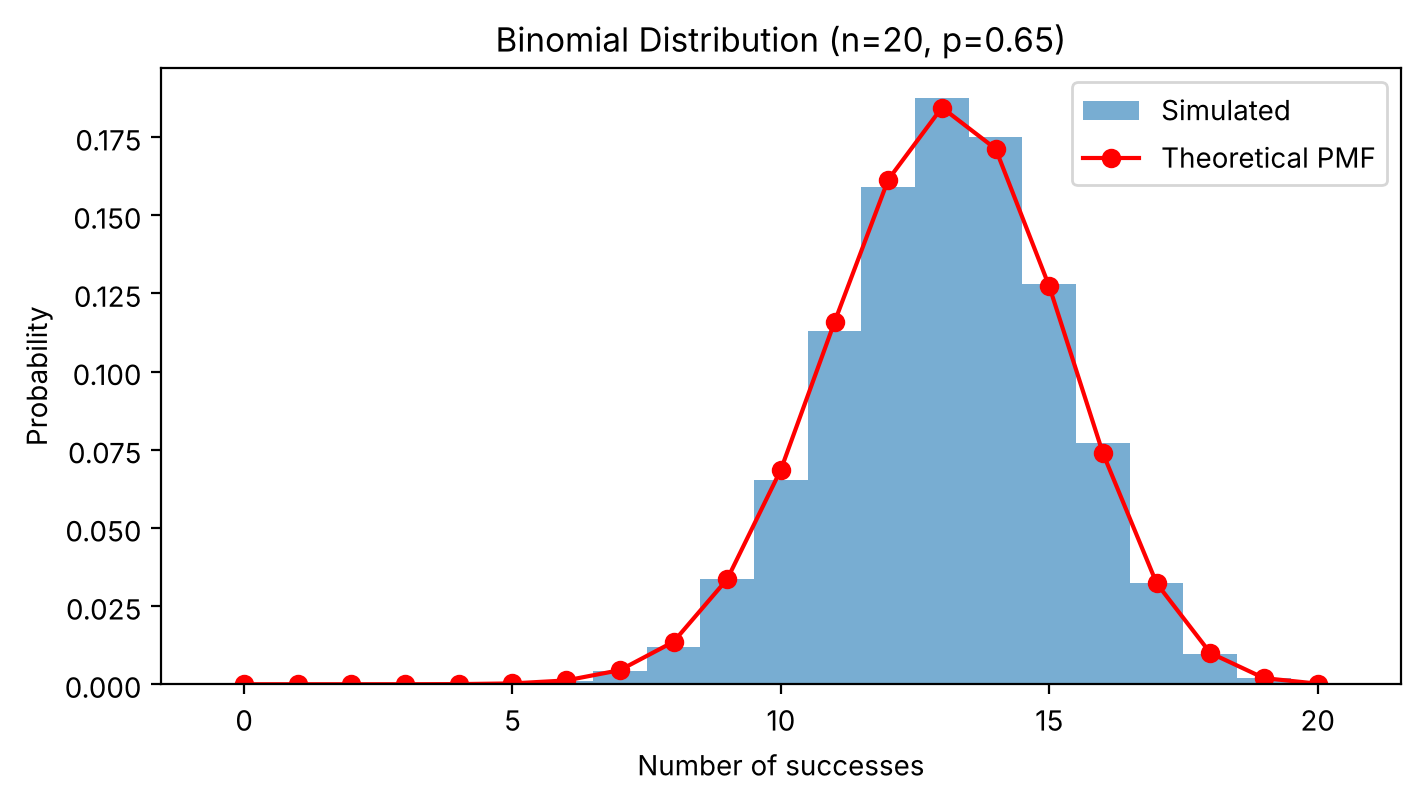

In [10]:
n_trials = 20
success_prob = 0.65

# Simulation
binom_samples = np.random.binomial(n=n_trials, p=success_prob, size=10000)
print("Simulated mean:", round(binom_samples.mean(), 3), "| Theoretical mean:", n_trials * success_prob)
print("Simulated std :", round(binom_samples.std(), 3), "| Theoretical std :", round(np.sqrt(n_trials * success_prob * (1 - success_prob)), 3))

# Theoretical PMF
k = np.arange(0, n_trials + 1)
pmf = stats.binom.pmf(k, n_trials, success_prob)
print("\nP(X = 13) =", round(stats.binom.pmf(13, n_trials, success_prob), 4))
print("P(X >= 15) =", round(1 - stats.binom.cdf(14, n_trials, success_prob), 4))

plt.figure(figsize=(8, 4))
plt.hist(binom_samples, bins=np.arange(-0.5, n_trials + 1.5, 1), density=True, alpha=0.6, label="Simulated")
plt.plot(k, pmf, "ro-", label="Theoretical PMF")
plt.title("Binomial Distribution (n=20, p=0.65)")
plt.xlabel("Number of successes"); plt.ylabel("Probability"); plt.legend()
plt.show()

### 2.5 Normal and uniform distributions

Normal  -> mean: 50.289, std: 10.237


Uniform -> mean: 0.498, std: 0.296 (theory: mean 0.5, std 0.289)


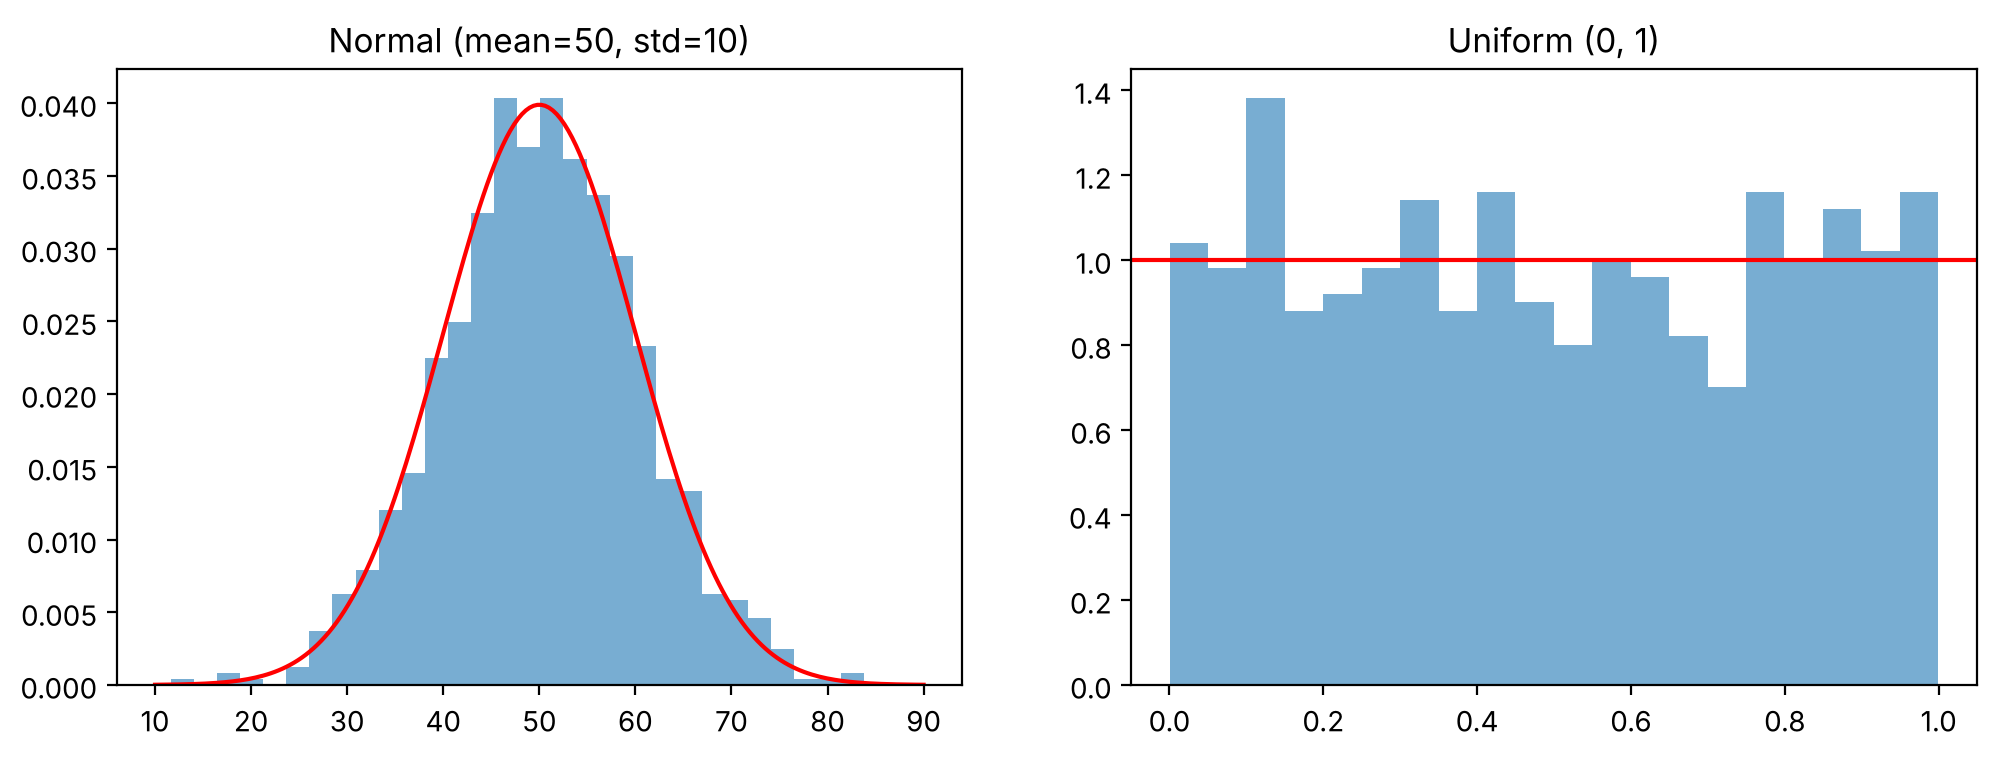

In [11]:
normal_mean, normal_std = 50, 10
uniform_low, uniform_high = 0, 1

normal_samples = np.random.normal(normal_mean, normal_std, 1000)
uniform_samples = np.random.uniform(uniform_low, uniform_high, 1000)

print("Normal  -> mean: %.3f, std: %.3f" % (normal_samples.mean(), normal_samples.std()))
print("Uniform -> mean: %.3f, std: %.3f (theory: mean 0.5, std %.3f)" % (uniform_samples.mean(), uniform_samples.std(), np.sqrt(1/12)))

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].hist(normal_samples, bins=30, density=True, alpha=0.6)
x = np.linspace(10, 90, 200)
ax[0].plot(x, stats.norm.pdf(x, normal_mean, normal_std), "r")
ax[0].set_title("Normal (mean=50, std=10)")
ax[1].hist(uniform_samples, bins=20, density=True, alpha=0.6)
ax[1].axhline(1, color="r")
ax[1].set_title("Uniform (0, 1)")
plt.show()

**Interpretation:** The normal samples form a bell curve centred near 50 with spread near 10. The uniform samples are spread evenly over 0 to 1, with a mean near 0.5.

---
## Task 3 – Descriptive Statistics

In [12]:
sales_data = [120, 135, 150, 145, 160, 155, 170, 165, 180, 175,
              190, 200, 210, 195, 185, 175, 165, 155, 145, 135]
s = pd.Series(sales_data)
print("Number of observations:", len(s))

Number of observations: 20


### 3.1 Central tendency

In [13]:
mean_val = np.mean(sales_data)
median_val = np.median(sales_data)
modes = statistics.multimode(sales_data)
print("Mean  :", mean_val)
print("Median:", median_val)
print("Mode(s):", sorted(modes), "(each occurs", sales_data.count(modes[0]), "times)")

Mean  : 165.5
Median: 165.0
Mode(s): [135, 145, 155, 165, 175] (each occurs 2 times)


### 3.2 Dispersion

In [14]:
data_range = max(sales_data) - min(sales_data)
variance_pop = np.var(sales_data)
variance_sample = np.var(sales_data, ddof=1)
std_pop = np.std(sales_data)
std_sample = np.std(sales_data, ddof=1)
print("Range:", data_range, f"(min {min(sales_data)}, max {max(sales_data)})")
print("Variance (population):", round(variance_pop, 3), "| (sample):", round(variance_sample, 3))
print("Std dev  (population):", round(std_pop, 3), "| (sample):", round(std_sample, 3))

Range: 90 (min 120, max 210)
Variance (population): 534.75 | (sample): 562.895
Std dev  (population): 23.125 | (sample): 23.725


### 3.3 Skewness and kurtosis

In [15]:
skewness = stats.skew(sales_data)
kurt = stats.kurtosis(sales_data)   # excess kurtosis (normal = 0)
print("Skewness:", round(skewness, 4))
print("Excess kurtosis:", round(kurt, 4))

Skewness: 0.0301
Excess kurtosis: -0.707


### 3.4 Interpretation

Skewness = 0.030 -> the distribution is approximately symmetric.
Mean vs median: 165.5 vs 165.0
Kurtosis < 0 -> flatter than a normal curve (platykurtic), few extreme values.


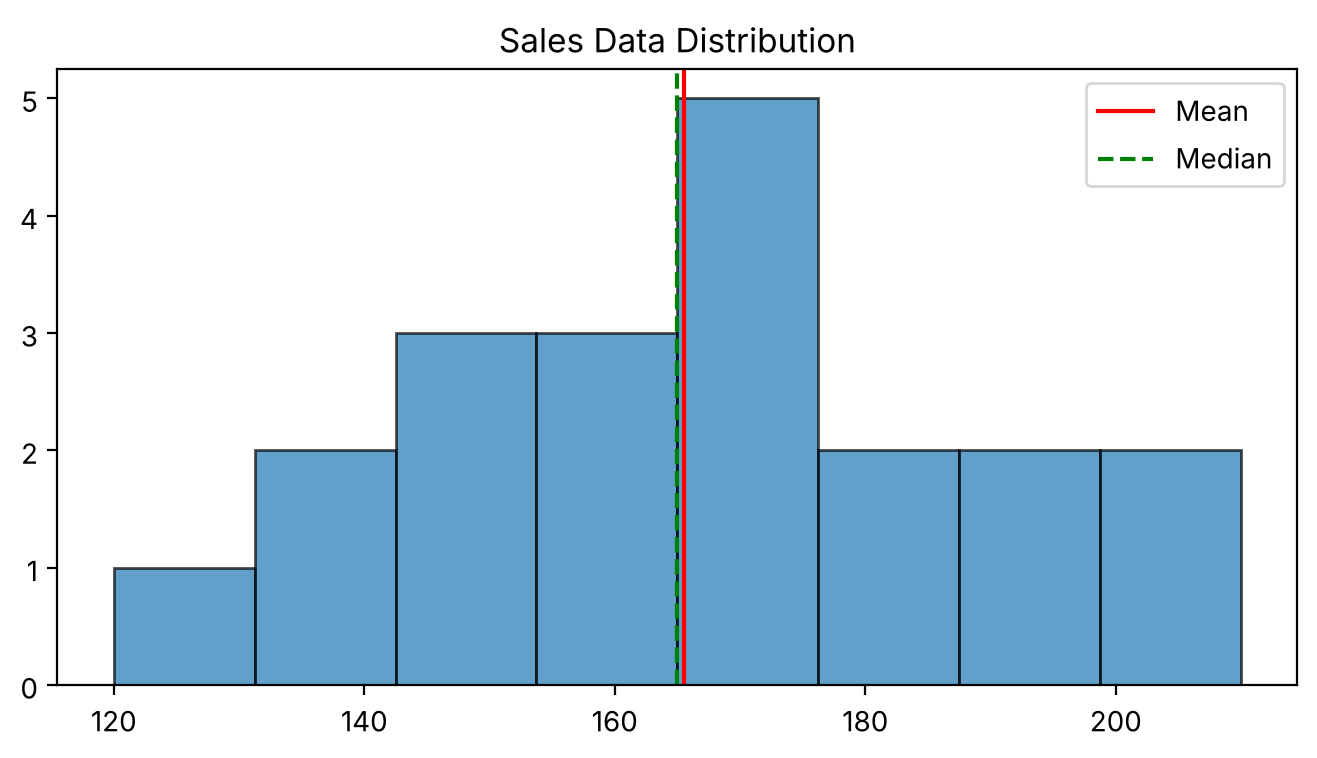

In [16]:
if abs(skewness) < 0.5:
    shape = "approximately symmetric"
elif skewness > 0:
    shape = "positively skewed"
else:
    shape = "negatively skewed"
print(f"Skewness = {skewness:.3f} -> the distribution is {shape}.")
print("Mean vs median:", mean_val, "vs", median_val)

if kurt < -0.5:
    print("Kurtosis < 0 -> flatter than a normal curve (platykurtic), few extreme values.")
elif kurt > 0.5:
    print("Kurtosis > 0 -> heavier tails than a normal curve (leptokurtic).")
else:
    print("Kurtosis is close to 0 -> tail weight similar to a normal curve (mesokurtic).")

plt.figure(figsize=(8, 4))
plt.hist(sales_data, bins=8, edgecolor="black", alpha=0.7)
plt.axvline(mean_val, color="r", label="Mean")
plt.axvline(median_val, color="g", linestyle="--", label="Median")
plt.title("Sales Data Distribution"); plt.legend(); plt.show()

### Conclusion
- **Symmetry:** mean (165.5) and median (165) are almost equal and skewness is about 0.03, so the sales data is **approximately symmetric** (very slightly positively skewed, not meaningfully).
- **Shape:** excess kurtosis is about -0.71, so the distribution is flatter than a normal curve with light tails.
- **Mode:** the data is multimodal. Five values (135, 145, 155, 165, 175) each appear twice.
- **Spread:** sales range from 120 to 210 (range 90) with a sample standard deviation of about 23.7.
- **Overall:** sales are stable and evenly spread around 165, with no extreme outliers, which makes the data suitable for models that assume roughly symmetric inputs.